# v2.08 — v2.07 with the B2 "true data" label (2 classes, next day; validation only)

**One change on top of v2.07** (Siwat, 2026-11-03, `configs/v2_08.json`; label decision `claude/decision-2026-11-03-binary-label-b2.md`):
- **What changes:** the label. **0 = Down** if tomorrow's raw close is below today's, **1 = Not-down** (up or unchanged) otherwise, inside one price segment. Raw Siamchart closes (no split / dividend adjustment). The trend head has 2 outputs.
- **What stays:** everything else is v2.07: 1-day horizon only, no price head, news-robust training (p 0.2), plain cross-entropy (no class weights), kept epoch on the hold-out macro-F1, the same rows and seeds.

**Class balance:** Not-down is 56.5% of training rows and 56.6% of validation rows, so accuracy alone overstates skill (always "Not-down" scores about 0.566). Macro-F1 is the headline.

**Status:** a secondary analysis. The pre-registered primary label stays the 3-class k × σ label (success-band amendment rule 5).

**Runtime:** A100 or L4, Colab only (Linux). Runtime → Run all. About 1 h of training, then about 2 min for the comparison. No post-hoc step (Siwat: raw only).

**Adopt rule** (pre-registered, `claude/log-entry-2026-11-03-v2-08-design.md`), raw model, validation macro-F1 over the 2 classes, paired 95% date-block intervals:
- **(a)** v2.08 − XGBoost (B2 label, fit rows) entirely above 0;
- **(b)** v2.08 − random calls at the training imbalance (P(Not-down) = 0.565; 100 draws) entirely above 0.

Outputs: `Senior/results/v2xx/<GPU>/v2_08*`, `Senior/results/v2_08_vs_b2_baselines.json`. Test block sealed.

In [1]:
!nvidia-smi -L
import torch
name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'none'
mem = torch.cuda.get_device_properties(0).total_memory / 2**30 if torch.cuda.is_available() else 0
print(f'GPU: {name}, {mem:.0f} GB')
GPU_TAG = 'A100' if 'A100' in name else 'L4' if 'L4' in name else None
assert GPU_TAG, 'stop: switch the runtime to an A100 or L4 GPU (Runtime -> Change runtime type)'

GPU 0: NVIDIA A100-SXM4-40GB (UUID: GPU-fa34f860-7f1f-96d4-6e49-aaf99d002cfe)
GPU: NVIDIA A100-SXM4-40GB, 39 GB


In [2]:
from google.colab import drive
drive.mount('/content/drive')
import hashlib, json, os, subprocess, sys
from pathlib import Path
SENIOR = '/content/drive/MyDrive/Senior'
PRICE_DIR, RES = f'{SENIOR}/prices', f'{SENIOR}/results'
OUT = f'{RES}/v2xx/{GPU_TAG}'
V208 = f'{OUT}/v2_08.json'
CMP = f'{RES}/v2_08_vs_b2_baselines.json'
for f in [f'{PRICE_DIR}/set50_union_2019_2025.csv', f'{PRICE_DIR}/yahoo_events_2019_2025.csv']:
    assert os.path.exists(f), f'stop: missing {f}'
os.makedirs(OUT, exist_ok=True)

def stream(args):
    # stream a script's output into the notebook and stop on failure
    p = subprocess.Popen(args, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        if 'defined on' not in line and 'not writable' not in line and 'from_numpy' not in line:
            print(line, end='', flush=True)
    if p.wait() != 0:
        raise SystemExit(f'stop: {" ".join(args[1:3])} failed (exit {p.returncode}); see the lines above')

Mounted at /content/drive


In [3]:
!rm -rf /content/Senior-Project && git clone -q https://github.com/Smith8bit/Senior-Project.git /content/Senior-Project
%cd /content/Senior-Project
!git log --oneline -1
for f in ['configs/v2_08.json', 'scripts/train_v2xx.py', 'src/labels.py', 'src/metrics.py', 'src/posthoc.py', 'src/train_utils.py', 'src/run_config.py', 'tests/test_no_price_head.py', 'tests/test_one_horizon.py', 'tests/test_b2_label.py', 'src/proposal_model.py',
          'scripts/compare_b2.py', 'scripts/plot_v2xx_training.py']:
    assert os.path.exists(f), f'stop: push the v2.08 code first ({f} missing)'
    print(f, hashlib.sha256(open(f, 'rb').read()).hexdigest()[:12])
!mkdir -p data/raw/prices/siamchart data/raw/prices/yahoo
!cp "$PRICE_DIR/set50_union_2019_2025.csv" data/raw/prices/siamchart/
!cp "$PRICE_DIR/yahoo_events_2019_2025.csv" data/raw/prices/yahoo/
expected = {'data/raw/prices/siamchart/set50_union_2019_2025.csv': '9d7ce4c3e72a974979566dc089d5b8819af54dc24f62b71240f5b4716b556e6f',
            'data/raw/prices/yahoo/yahoo_events_2019_2025.csv': 'd021a58df95fa487f1e49eb50617f6b3187b025b6377235c6180166b1ec84d53',
            'data/derived/sentiment_scores.csv': '7369fd981c4ccffc017d6d5de50ed95c6a4ac4d843bbc6053366029ce614bb1b'}
for path, h in expected.items():
    got = hashlib.sha256(open(path, 'rb').read()).hexdigest()
    print('OK ' if got == h else 'MISMATCH ', path)
    assert got == h, 'stop: a file differs from the frozen copy'
sys.path.insert(0, 'src'); sys.path.insert(0, 'scripts')
import run_config as RC
cfg = RC.load('configs/v2_08.json')
print('v2.08 label:', cfg['protocol']['label_rule'], '| horizons:', cfg['protocol']['horizons'], '| price head:', cfg['model']['price_head'], '| loss:', json.dumps(cfg['loss']), '| training:', json.dumps(cfg['training']))

/content/Senior-Project
fca5c39 (HEAD -> main, origin/main, origin/HEAD) Add v2.08 B2 binary-label experiment
configs/v2_08.json 2ae2b2478a05
scripts/train_v2xx.py 829db802d0e1
src/labels.py 626333b18f40
src/metrics.py 2cd53b60dc1e
src/posthoc.py 1f17ef46448a
src/train_utils.py 85ea33ee399b
src/run_config.py 2e25754d9351
tests/test_no_price_head.py ee2a4d4cfef5
tests/test_one_horizon.py b30d97074ff7
tests/test_b2_label.py bdd8c300f36c
src/proposal_model.py a1335af76a33
scripts/compare_b2.py 5dffc6595b63
scripts/plot_v2xx_training.py b6d050cfd143
OK  data/raw/prices/siamchart/set50_union_2019_2025.csv
OK  data/raw/prices/yahoo/yahoo_events_2019_2025.csv
OK  data/derived/sentiment_scores.csv
v2.08 label: b2_raw_close | horizons: [1] | price head: False | loss: {"price_target": "log_return", "weighting": "fixed", "w_trend": 1.0, "w_price": 0, "price_loss": "mse", "huber_delta": null} | training: {"lr": 0.0001, "lr_schedule": "constant", "weight_decay": 0.01, "batch_size": 256, "max_epochs

In [4]:
# Tests (about 15 minutes); the notebook stops if any fails
for t in ['tests/test_v2xx.py', 'tests/test_v2xx_training.py', 'tests/test_news_blank.py', 'tests/test_grad_diag.py', 'tests/test_no_price_head.py', 'tests/test_one_horizon.py', 'tests/test_b2_label.py',
          'tests/test_step0_v2_03beta.py']:
    r = subprocess.run(['python', t], capture_output=True, text=True)
    print(f'--- {t}'); print('\n'.join(l for l in r.stdout.splitlines() if 'defined on' not in l and '    seed' not in l)[-2500:])
    assert r.returncode == 0 and 'FAIL' not in r.stdout, f'stop: {t} failed\n' + r.stderr[-2000:]

--- tests/test_v2xx.py
 91,841 equals the hand formula
PASS batchnorm/independent: both heads receive gradient
PASS batchnorm/mixed: output shapes
PASS batchnorm/mixed: scale weights are a softmax
PASS batchnorm/mixed: heads 128->128->64->3 / ->9 and Linear layer 128 (slides 12-13)
PASS batchnorm/mixed: weight count 67,841 equals the hand formula
PASS batchnorm/mixed: both heads receive gradient
PASS independent: day t always reaches the output; the leftover oldest day is the one dropped
PASS mixed: day t always reaches the output; the leftover oldest day is the one dropped
PASS v2.01 numbers: tokens 126 / 25 / 6; the week scale skips the oldest day
PASS v2.01 numbers: weight count 1,587,175 equals the hand formula
PASS v2.02 numbers: tokens 63 / 25 / 6, weight count 1,579,239 = hand formula = 1,579,239
PASS PatchTST layer: BatchNorm1d over d_model, GELU feed-forward, attention dropout 0 (official defaults)
PASS post-norm order: normalise after each residual add
PASS eval mode: a row's

In [5]:
# 1. Train v2.08 (B2 label, 1-day horizon only, no price head): 3 seeds one after another
def done(path, n=3):
    try:
        r = json.load(open(path)); return len(r['runs']) == n and 'summary' in r
    except Exception:
        return False
if done(V208):
    print('v2.08: already trained')
else:
    stream(['python', '-u', 'scripts/train_v2xx.py', '--config', 'configs/v2_08.json', '--out', V208])

config v2.08: {"inputs": {"price_channels": ["open", "high", "low", "close", "volume"], "ohlc_return_base": "previous_close", "indicators": ["sma", "ema", "rsi", "macd", "bb_pctb", "adx"], "sma_periods": [9, 21, 60], "ema_periods": [9, 21, 60], "rsi_period": 14, "macd_fast": 12, "macd_slow": 26, "bb_period": 20, "bb_width_k": 2.0, "adx_period": 14, "sentiment": ["p_pos", "p_neg", "p_neu"], "sentiment_no_news": "uniform", "stock_identity": ["stock_id", "sector_id"]}, "model": {"family": "proposal_msp", "lookback": 126, "patch_lengths": [2, 5, 21], "patch_strides": [2, 5, 21], "channel_mode": "independent", "revin": true, "encoder_norm": "batchnorm", "d_model": 128, "n_heads": 16, "n_layers": 3, "d_ff": 256, "dropout": 0.2, "pooling": "mean", "scale_fusion": "attention", "fusion_hidden": 128, "d_stock": 32, "d_sector": 18, "stock_id_dropout": 0.1, "trunk_width": 128, "head_hidden": [128, 64], "head_dropout": 0.2, "price_head": false}, "loss": {"price_target": "log_return", "weighting": "

label b2_raw_close ['down', 'not_down'] | not-down share train 0.5654 | fit / hold-out / val [0.5667, 0.5608, 0.5661]
v2.08 macro-F1 0.5097 ± 0.0043 | accuracy 0.5302 ± 0.0031
  floor majority_class               macro-F1 0.3615   accuracy 0.5661
  floor stratified_random_expected   macro-F1 0.5000   accuracy 0.5086
  floor trend_continues              macro-F1 0.4814   accuracy 0.4908
  floor trend_reverses               macro-F1 0.5092   accuracy 0.5092
seed 4539913 epochs 30 kept 30 hold-out F1 0.4942 val F1 0.5067 confusion [[down],[not down]] [[1574, 2885], [1927, 3891]] weights 1553821 minutes 32.5
seed 9574315 epochs 30 kept 26 hold-out F1 0.5068 val F1 0.5078 confusion [[down],[not down]] [[1700, 2759], [2105, 3713]] weights 1553821 minutes 32.5
seed 2253758 epochs 30 kept 25 hold-out F1 0.5015 val F1 0.5147 confusion [[down],[not down]] [[1761, 2698], [2110, 3708]] weights 1553821 minutes 32.4
seed ensemble {'macro_f1': 0.5088, 'accuracy': 0.5342, 'confusion': [[1577, 2882], [

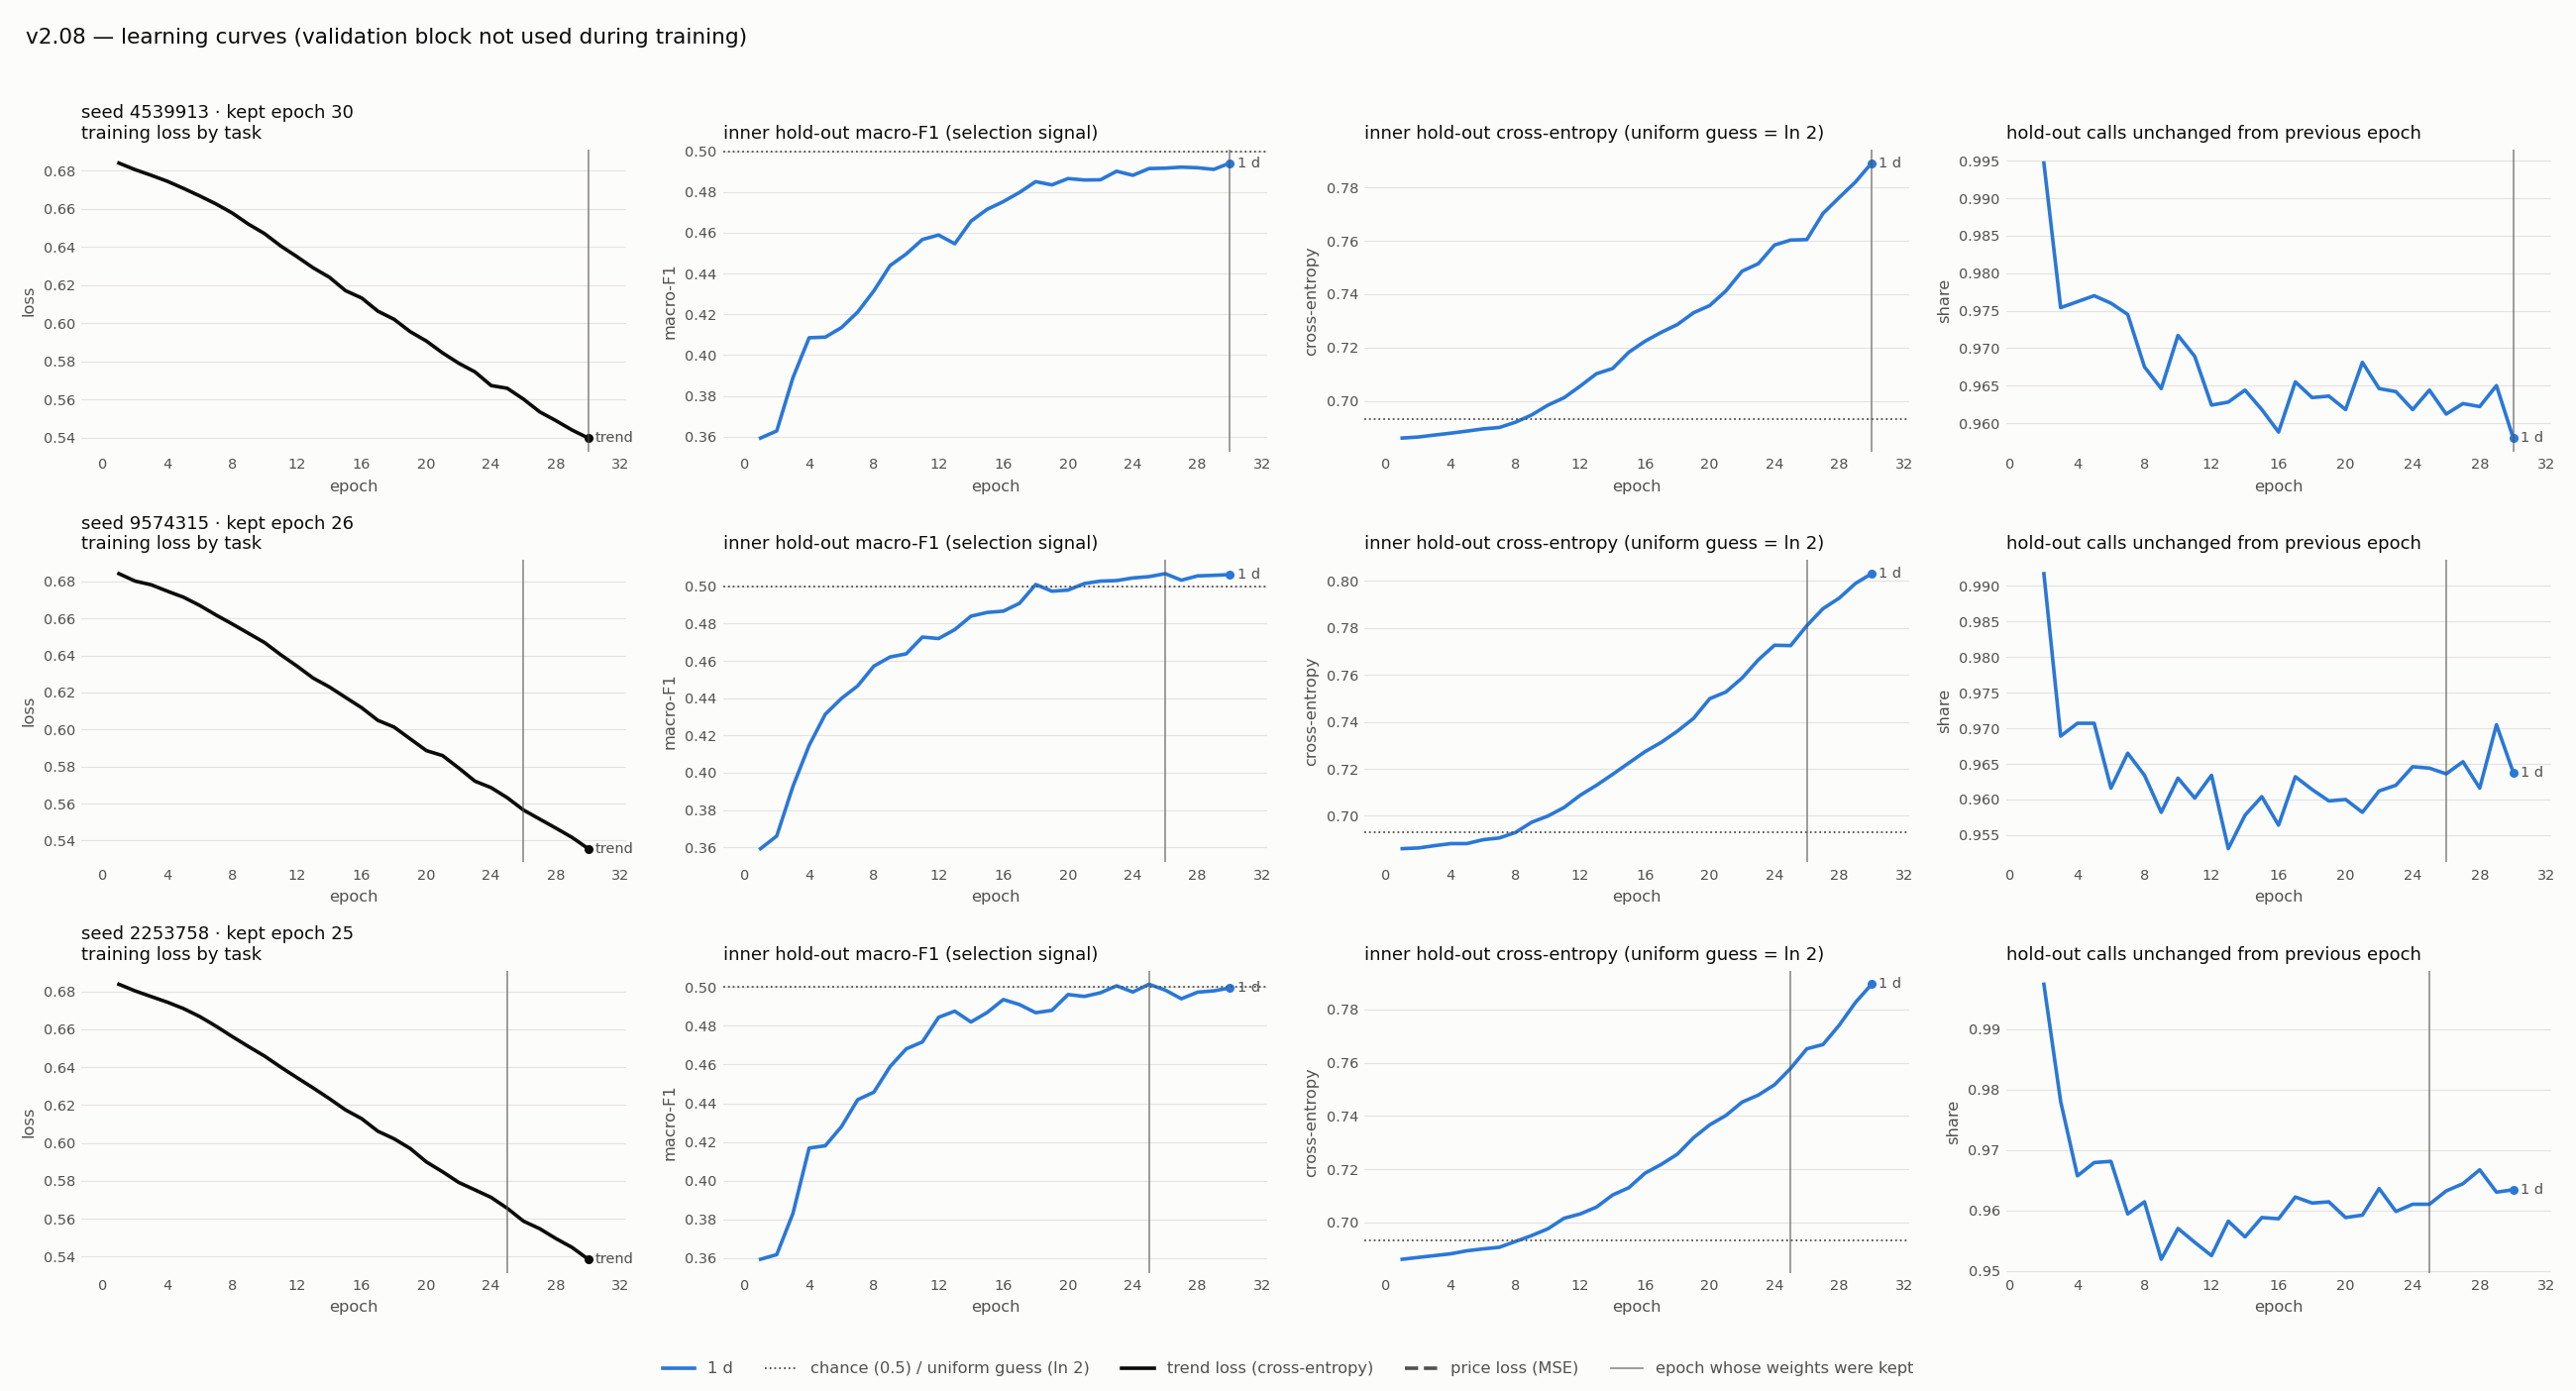

saved /content/drive/MyDrive/Senior/results/v2xx/A100/v2_08_calls.png


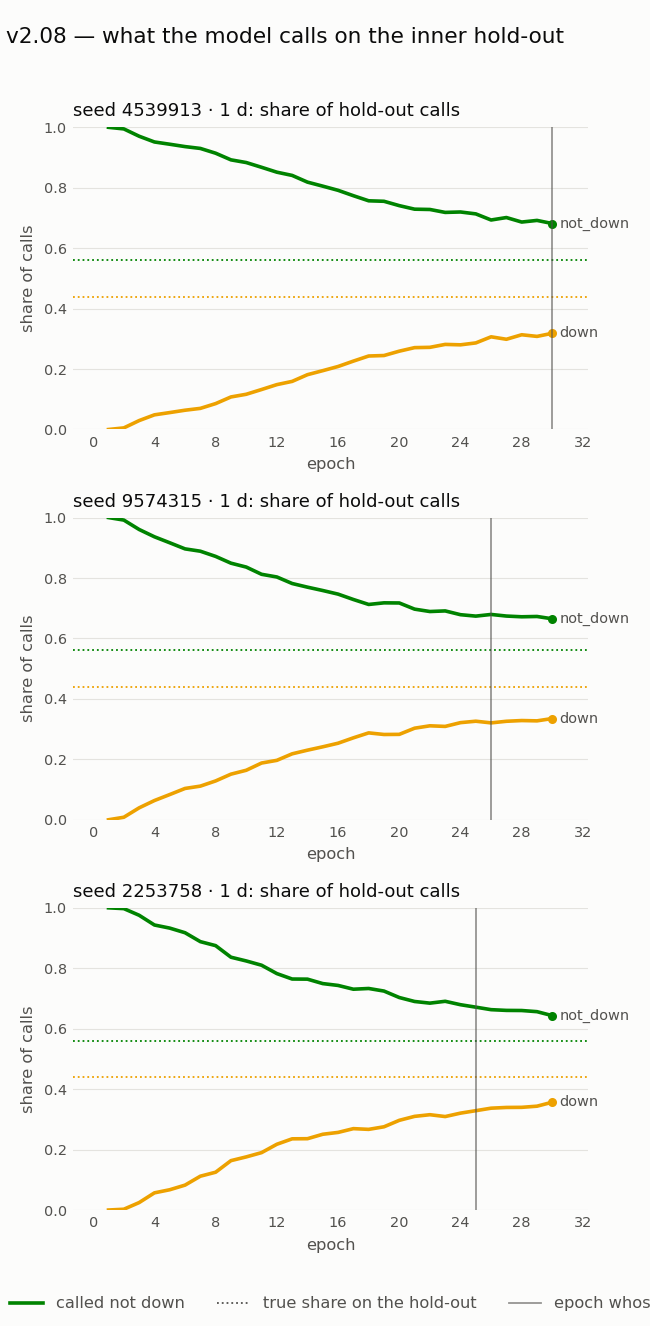

In [6]:
# 2. Summary beside the B2 floors (computed in the run), and the learning curves
r = json.load(open(V208)); s, fl = r['summary']['model']['h1'], r['floors']['h1']
print('label', r['label']['rule'], r['label']['classes'], '| not-down share train', r['label']['train_class_shares'][1],
      '| fit / hold-out / val', [x[1] for x in r['label']['class_shares'].values()])
print(f"v2.08 macro-F1 {s['macro_f1']['mean']:.4f} ± {s['macro_f1']['std']:.4f} | accuracy {s['accuracy']['mean']:.4f} ± {s['accuracy']['std']:.4f}")
for k in ('majority_class', 'stratified_random_expected', 'trend_continues', 'trend_reverses'):
    print(f"  floor {k:28s} macro-F1 {fl[k]['macro_f1']:.4f}   accuracy {fl[k].get('accuracy', float('nan')):.4f}")
for x in r['runs']:
    print('seed', x['seed'], 'epochs', x['epochs_run'], 'kept', x['best_epoch'], 'hold-out F1', x['best_inner_es_macro_f1'],
          'val F1', x['val']['h1']['macro_f1'], 'confusion [[down],[not down]]', x['val']['h1']['confusion'],
          'weights', x['params']['total'], 'minutes', round(x['seconds'] / 60, 1))
if 'seed_ensemble' in r:
    print('seed ensemble', r['seed_ensemble']['val']['h1'])
from IPython.display import Image, display
import importlib, plot_v2xx_training as PT
for png in (PT.plot(Path(V208)), PT.plot_calls(Path(V208))):
    if png:
        print('saved', png); display(Image(filename=str(png)))

In [7]:
# 3. v2.08 vs XGBoost (B2) and random at the B2 imbalance on the same rows, and the pre-registered adopt rule
stream(['python', 'scripts/compare_b2.py', '--run', V208, '--out', CMP])

  XGBoost (B2) seed 4539913: trained on 44060 fit rows
  XGBoost (B2) seed 9574315: trained on 44060 fit rows
  XGBoost (B2) seed 2253758: trained on 44060 fit rows

v2.08 on validation (10277 rows; actual down / not down 43.4% / 56.6%; train not-down share 56.5%)
                         macro-F1  95% interval     accuracy  F1 down F1 n-down calls down
v2.08                      0.5098  [0.5002, 0.5171]   0.5302   0.4099    0.6096      36.2%
v2.08_seed_ensemble        0.5088  [0.496, 0.5184]    0.5342   0.3972    0.6205      33.9%
xgboost_b2                 0.4382  [0.4251, 0.4523]   0.5626   0.1739    0.7025       9.6%
random_b2_imbalance        0.5001  [0.499, 0.5007]    0.5088   0.4346    0.5657      43.5%
majority_class             0.3615  [0.3496, 0.3731]   0.5661   0.0000    0.7230       0.0%
direction_continues        0.4814  [0.4685, 0.4945]   0.4908   0.4117    0.5512      43.2%
direction_reverses         0.5092  [0.492, 0.5261]    0.5092   0.5103    0.5081      56.8%

paired

**Reading the result**
- **ADOPT RULE** (last block): v2.08 must beat both XGBoost (B2) and random calls at the training imbalance, each with the paired interval entirely above 0. Raw model.
- Random at the imbalance has an expected macro-F1 of **0.5**; always "Not-down" scores about 0.37 macro-F1 but 0.566 accuracy.
- Not comparable with v2.01–v2.07 (different label).
- Send the printout to Claude.